# embher on simulated data

A self-contained example: no model weights, no GPU, no external files. It uses the torch-free parts of embher (`pip install "embher[heritability]"`).

1. Simulate genotypes and a phenotype with a known heritability.
2. Estimate it with exact AI-REML (`embher.heritability.fit_reml`) and Haseman-Elston regression (`he_fit`).
3. Simulate an embedding that partly reflects the genetic value, whiten it (`embher.embedding.whiten_embeddings`), use it as a kernel, and compare with a donor-shuffled null.

The Borzoi/AlphaGenome capture and attribution tools (`embher-capture`, `embher-attribute`) need weights and a GPU, so they are not run here; see the README.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from embher.heritability import build_grm, fit_reml, he_fit
from embher.embedding import whiten

rng = np.random.default_rng(0)
n, m, h2_true = 1500, 3000, 0.5

## 1. Genotypes and phenotype

Donors x variants dosages (0/1/2) with random allele frequencies; every variant has a small effect, and the phenotype is the genetic value plus noise so that the genetic share of the variance is `h2_true`.

In [2]:
maf = rng.uniform(0.05, 0.5, m)
dosage = rng.binomial(2, maf, size=(n, m)).astype(float)

z = (dosage - 2 * maf) / np.sqrt(2 * maf * (1 - maf))          # standardised genotypes
g = z @ rng.normal(0, np.sqrt(h2_true / m), m)                 # genetic value, var ~ h2_true
y = g + rng.normal(0, np.sqrt(1 - h2_true), n)                 # phenotype, var ~ 1

X = np.column_stack([np.ones(n), rng.normal(size=n)])          # intercept + one covariate
K, n_used = build_grm(dosage)
print(f"GRM {K.shape}, {n_used} variants")

GRM (1500, 1500), 3000 variants


## 2. Heritability from the genotype GRM

`fit_reml` and `he_fit` take a list of kernels, the phenotype and a design matrix that already contains the intercept.

In [3]:
reml = fit_reml([K], y, X)
print(f"REML  h2 = {reml['h2']:.3f} +/- {reml['h2_se']:.3f}   (true {h2_true})")

he = he_fit([K], y[:, None], X, jackknife=False)
theta, a = he["theta"][:, 0], he["a"]
h2_he = a[0] * theta[0] / (a * theta).sum()
print(f"HE    h2 = {h2_he:.3f}")

REML  h2 = 0.533 +/- 0.048   (true 0.5)
HE    h2 = 0.561


## 3. An embedding as a kernel

A stand-in for a model's embedding: 200 features that mix the genetic value with donor-specific structure unrelated to the phenotype. `whiten_embeddings` standardises the features and returns the top-k PC scores with unit variance; their GRM is the embedding kernel.

In [4]:
n_feat = 200
loading = rng.normal(size=n_feat)
latent = rng.normal(size=(n, 10)) @ rng.normal(size=(10, n_feat))          # unrelated structure
Z = 1.5 * np.outer(g / g.std(), loading) + latent + rng.normal(size=(n, n_feat))

def embedding_h2(Z, y, n_pcs=10):
    S = whiten.whiten_embeddings(Z, n_pcs=n_pcs, verbose=False)
    K_emb = S @ S.T / S.shape[1]
    return fit_reml([K_emb], y, X)

emb = embedding_h2(Z, y)
null = [embedding_h2(Z[rng.permutation(n)], y)["h2"] for _ in range(20)]
print(f"embedding h2 = {emb['h2']:.3f} +/- {emb['h2_se']:.3f}")
print(f"shuffled donors: mean {np.mean(null):.3f}, max {np.max(null):.3f}  (20 shuffles)")

embedding h2 = 0.507 +/- 0.113
shuffled donors: mean 0.001, max 0.008  (20 shuffles)


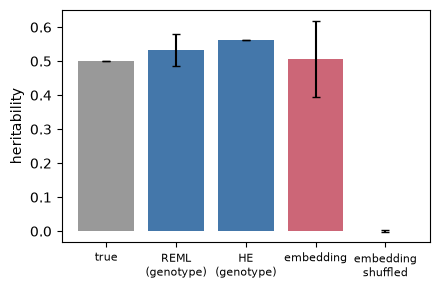

In [5]:
fig, ax = plt.subplots(figsize=(4.5, 3))
labels = ["true", "REML\n(genotype)", "HE\n(genotype)", "embedding", "embedding\nshuffled"]
vals = [h2_true, reml["h2"], h2_he, emb["h2"], np.mean(null)]
errs = [0, reml["h2_se"], 0, emb["h2_se"], np.std(null)]
ax.bar(labels, vals, yerr=errs, color=["#999", "#4477aa", "#4477aa", "#cc6677", "#ddd"], capsize=3)
ax.set_ylabel("heritability")
plt.xticks(fontsize=8); plt.tight_layout(); plt.show()

The genotype estimates recover the simulated value. Because the genetic value is a strong direction in this embedding, the whitened top PCs carry it and the embedding kernel recovers about the genotype heritability; shuffling donors removes it. With a weaker genetic signal the same estimate drops towards 0, since whitening gives every retained PC equal weight.

Next: `embher.heritability.bin_masks` for MAF/LD-binned multi-kernel fits, `fit_reml(..., nonneg=True)` for the constrained fit with its LRT, and `embher-capture` to produce real embeddings.